In [1]:
import time, os, random, copy
import numpy as np
import cv2
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Cihaz:', device)

Cihaz: cpu


In [2]:
MEAN, STD = 0.1307, 0.3081
tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

full_train = datasets.MNIST('data', train=True,  download=True, transform=tfm)
test_set   = datasets.MNIST('data', train=False, download=True, transform=tfm)

train_set, val_set = random_split(full_train, [54000, 6000],
                                  generator=torch.Generator().manual_seed(SEED))
print('Train:', len(train_set), '| Validation:', len(val_set), '| Test:', len(test_set))

100%|██████████| 9.91M/9.91M [00:00<00:00, 134MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 33.3MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 67.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.87MB/s]


Train: 54000 | Validation: 6000 | Test: 10000


In [3]:
class MLP(nn.Module):
    def __init__(self, hidden=(256, 128), dropout=0.0):
        super().__init__()
        layers, prev = [nn.Flatten()], 784
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 10))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * y.size(0)
            correct  += (out.argmax(1) == y).sum().item()
            total    += y.size(0)
    return loss_sum / total, correct / total

def train_model(cfg):
    torch.manual_seed(SEED)
    model = MLP(cfg['hidden'], cfg.get('dropout', 0.0)).to(device)
    criterion = nn.CrossEntropyLoss()
    opt = (torch.optim.Adam(model.parameters(), lr=cfg['lr']) if cfg['optimizer'] == 'adam'
           else torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9))
    tl = DataLoader(train_set, batch_size=cfg['batch'], shuffle=True)
    vl = DataLoader(val_set,   batch_size=1000)
    hist = {'tr_loss':[], 'va_loss':[], 'tr_acc':[], 'va_acc':[]}
    best_state, best_va = None, -1
    t0 = time.time()
    for ep in range(cfg['epochs']):
        trl, tra = run_epoch(model, tl, criterion, opt)
        val, vaa = run_epoch(model, vl, criterion)
        for k, v in zip(hist, (trl, val, tra, vaa)): hist[k].append(v)
        if vaa > best_va: best_va, best_state = vaa, copy.deepcopy(model.state_dict())
        print(f"Epoch {ep+1:2d}/{cfg['epochs']} | train loss {trl:.4f} acc {tra:.4f} | val loss {val:.4f} acc {vaa:.4f}")
    model.load_state_dict(best_state)
    return model, hist, time.time() - t0

def evaluate_test(model):
    return run_epoch(model, DataLoader(test_set, batch_size=1000), nn.CrossEntropyLoss())

def plot_hist(h, title=''):
    ep = range(1, len(h['tr_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, h['tr_loss'], label='Train'); ax[0].plot(ep, h['va_loss'], label='Validation')
    ax[0].set_title(title + ' Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(ep, h['tr_acc'], label='Train'); ax[1].plot(ep, h['va_acc'], label='Validation')
    ax[1].set_title(title + ' Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

Hiperparametreler: {'hidden': (256, 128), 'optimizer': 'adam', 'lr': 0.001, 'batch': 128, 'epochs': 10, 'dropout': 0.0}
Epoch  1/10 | train loss 0.2900 acc 0.9142 | val loss 0.1472 acc 0.9555
Epoch  2/10 | train loss 0.1112 acc 0.9655 | val loss 0.1168 acc 0.9653
Epoch  3/10 | train loss 0.0752 acc 0.9764 | val loss 0.1015 acc 0.9725
Epoch  4/10 | train loss 0.0534 acc 0.9831 | val loss 0.0855 acc 0.9742
Epoch  5/10 | train loss 0.0411 acc 0.9865 | val loss 0.0825 acc 0.9755
Epoch  6/10 | train loss 0.0336 acc 0.9890 | val loss 0.0735 acc 0.9760
Epoch  7/10 | train loss 0.0274 acc 0.9911 | val loss 0.0881 acc 0.9755
Epoch  8/10 | train loss 0.0213 acc 0.9932 | val loss 0.0872 acc 0.9760
Epoch  9/10 | train loss 0.0180 acc 0.9939 | val loss 0.1018 acc 0.9745
Epoch 10/10 | train loss 0.0187 acc 0.9937 | val loss 0.1067 acc 0.9748


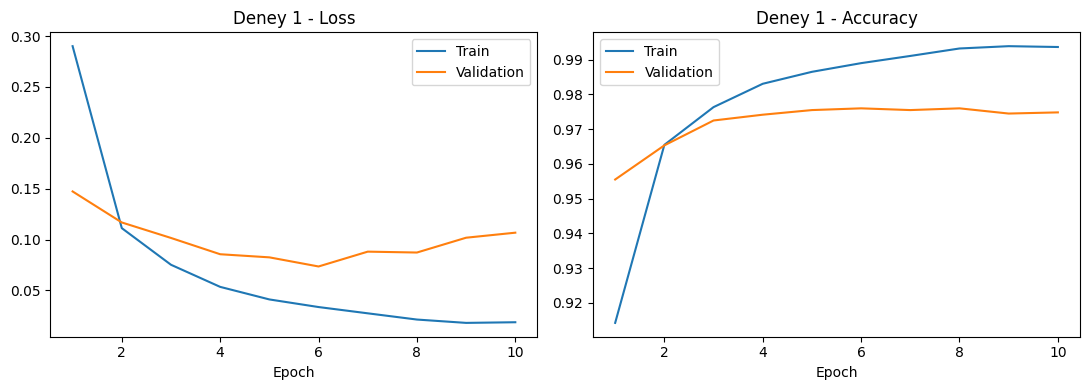

Training loss      : 0.0187
Validation loss    : 0.1067
Training accuracy  : 0.9937
Validation accuracy: 0.9748
Test accuracy      : 0.9790
Eğitim süresi      : 164.5 sn


In [4]:
BASE = dict(hidden=(256, 128), optimizer='adam', lr=1e-3, batch=128, epochs=10, dropout=0.0)
print('Hiperparametreler:', BASE)
model1, hist1, t1 = train_model(BASE)
plot_hist(hist1, 'Deney 1 -')

test_loss1, test_acc1 = evaluate_test(model1)
print(f"Training loss      : {hist1['tr_loss'][-1]:.4f}")
print(f"Validation loss    : {hist1['va_loss'][-1]:.4f}")
print(f"Training accuracy  : {hist1['tr_acc'][-1]:.4f}")
print(f"Validation accuracy: {hist1['va_acc'][-1]:.4f}")
print(f"Test accuracy      : {test_acc1:.4f}")
print(f"Eğitim süresi      : {t1:.1f} sn")

In [6]:
configs = {
  'A: 256-128, Adam, lr=1e-3 (baz)': dict(BASE),
  'B: 64-32,  Adam, lr=1e-3 (küçük)': dict(BASE, hidden=(64, 32)),
  'C: 512-256-128, Adam, lr=1e-3 (derin/geniş)': dict(BASE, hidden=(512, 256, 128)),
  'D: 256-128, SGD+mom, lr=0.01': dict(BASE, optimizer='sgd', lr=0.01),
  'E: 256-128, Adam, lr=1e-3, dropout=0.3': dict(BASE, dropout=0.3),
}
results = {}
for name, cfg in configs.items():
    print('\n==', name)
    m, h, t = train_model(cfg)
    results[name] = dict(model=m, hist=h, time=t)

print('\n{:<46}{:>9}{:>9}{:>9}{:>9}{:>9}'.format('Konfigürasyon','tr_loss','va_loss','tr_acc','va_acc','süre(s)'))
for n, r in results.items():
    h = r['hist']
    print('{:<46}{:>9.4f}{:>9.4f}{:>9.4f}{:>9.4f}{:>9.1f}'.format(
        n, h['tr_loss'][-1], h['va_loss'][-1], h['tr_acc'][-1], h['va_acc'][-1], r['time']))

best_name = max(results, key=lambda n: max(results[n]['hist']['va_acc']))
best_model = results[best_name]['model']
print("\nValidation'a göre en iyi:", best_name)
_, best_test_acc = evaluate_test(best_model)
print(f'Seçilen modelin TEST accuracy (tek sefer): {best_test_acc:.4f}')


== A: 256-128, Adam, lr=1e-3 (baz)
Epoch  1/10 | train loss 0.2900 acc 0.9142 | val loss 0.1472 acc 0.9555
Epoch  2/10 | train loss 0.1112 acc 0.9655 | val loss 0.1168 acc 0.9653
Epoch  3/10 | train loss 0.0752 acc 0.9764 | val loss 0.1015 acc 0.9725
Epoch  4/10 | train loss 0.0534 acc 0.9831 | val loss 0.0855 acc 0.9742
Epoch  5/10 | train loss 0.0411 acc 0.9865 | val loss 0.0825 acc 0.9755
Epoch  6/10 | train loss 0.0336 acc 0.9890 | val loss 0.0735 acc 0.9760
Epoch  7/10 | train loss 0.0274 acc 0.9911 | val loss 0.0881 acc 0.9755
Epoch  8/10 | train loss 0.0213 acc 0.9932 | val loss 0.0872 acc 0.9760
Epoch  9/10 | train loss 0.0180 acc 0.9939 | val loss 0.1018 acc 0.9745
Epoch 10/10 | train loss 0.0187 acc 0.9937 | val loss 0.1067 acc 0.9748

== B: 64-32,  Adam, lr=1e-3 (küçük)
Epoch  1/10 | train loss 0.4201 acc 0.8801 | val loss 0.2576 acc 0.9232
Epoch  2/10 | train loss 0.1882 acc 0.9430 | val loss 0.1811 acc 0.9435
Epoch  3/10 | train loss 0.1388 acc 0.9582 | val loss 0.1597 ac

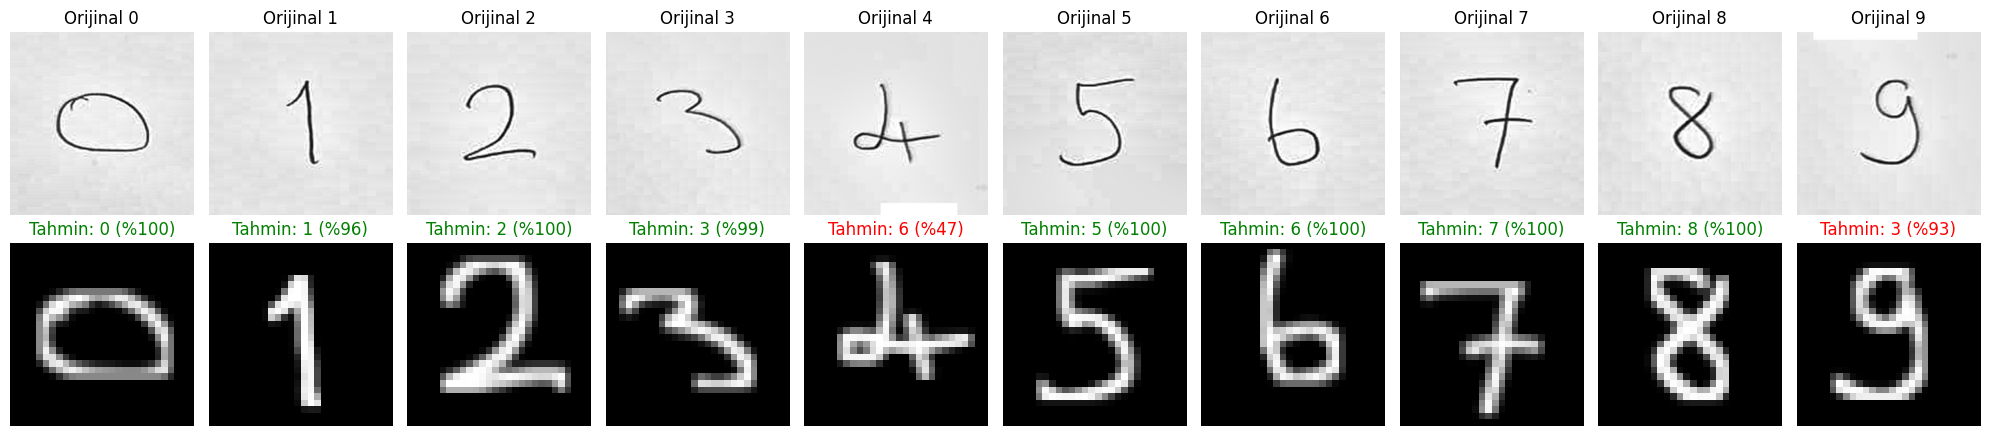

Kendi el yazımla 0-9 doğruluğu: 80%


In [7]:
def prepare(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    bg = cv2.GaussianBlur(cv2.dilate(g, np.ones((31, 31), np.uint8)), (0, 0), 15).astype(np.float32)
    ink = 1 - np.clip(g.astype(np.float32) / np.maximum(bg, 1), 0, 1)
    ink = np.clip(ink / (np.percentile(ink, 99.5) + 1e-6), 0, 1)
    mask = (ink > 0.35).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    big, keep = st[1:, 4].max(), np.zeros_like(mask)
    for k in range(1, n):
        if st[k, 4] >= 0.15 * big: keep[lab == k] = 1
    ink = ink * keep
    ys, xs = np.where(keep > 0)
    d = ink[ys.min():ys.max()+1, xs.min():xs.max()+1]
    k = max(3, int(max(d.shape) * 0.07)) | 1
    d = cv2.dilate(d, np.ones((k, k), np.float32))
    h, w = d.shape; s = 20 / max(h, w)
    d = cv2.resize(d, (max(1, round(w*s)), max(1, round(h*s))), interpolation=cv2.INTER_AREA)
    out = np.zeros((28, 28), np.float32)
    y0, x0 = (28 - d.shape[0]) // 2, (28 - d.shape[1]) // 2
    out[y0:y0+d.shape[0], x0:x0+d.shape[1]] = d
    yy, xx = np.indices(out.shape); tot = out.sum()
    cy, cx = (yy*out).sum()/tot, (xx*out).sum()/tot
    out = cv2.warpAffine(out, np.float32([[1, 0, 13.5-cx], [0, 1, 13.5-cy]]), (28, 28))
    return Image.fromarray((np.clip(out, 0, 1) * 255).astype(np.uint8))

def predict(model, pil_img):
    x = tfm(pil_img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(x), 1)[0]
    return p.argmax().item(), p.max().item()

DIGIT_DIR = 'custom_digits'
os.makedirs('custom_digits_28x28', exist_ok=True)
imgs = {d: prepare(f'{DIGIT_DIR}/{d}.jpeg') for d in range(10)}
for d, im in imgs.items(): im.save(f'custom_digits_28x28/{d}.png')

fig, ax = plt.subplots(2, 10, figsize=(20, 4.5))
for d in range(10):
    ax[0, d].imshow(Image.open(f'{DIGIT_DIR}/{d}.jpeg').convert('L'), cmap='gray')
    ax[0, d].axis('off'); ax[0, d].set_title(f'Orijinal {d}')
    pred, conf = predict(best_model, imgs[d])
    ax[1, d].imshow(imgs[d], cmap='gray'); ax[1, d].axis('off')
    ax[1, d].set_title(f'Tahmin: {pred} (%{conf*100:.0f})', color='green' if pred == d else 'red')
plt.tight_layout(); plt.show()

acc = np.mean([predict(best_model, imgs[d])[0] == d for d in range(10)])
print(f'Kendi el yazımla 0-9 doğruluğu: {acc*100:.0f}%')

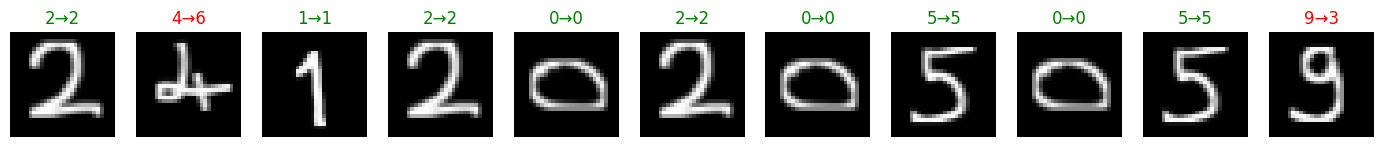

Gerçek numara : 24120205059
Model tahmini : 26120205053
Doğru haneler : 9 / 11


In [8]:
STUDENT_NO = '24120205059'

row = []
for ch in STUDENT_NO:
    d = int(ch)
    pred, conf = predict(best_model, imgs[d])
    row.append((ch, pred, conf))

fig, ax = plt.subplots(1, len(row), figsize=(1.6*len(row), 2.4))
ax = np.atleast_1d(ax)
for a, (ch, pred, conf) in zip(ax, row):
    a.imshow(imgs[int(ch)], cmap='gray'); a.axis('off')
    a.set_title(f'{ch}→{pred}', color='green' if int(ch) == pred else 'red')
plt.show()
print('Gerçek numara :', STUDENT_NO)
print('Model tahmini :', ''.join(str(p) for _, p, _ in row))
print('Doğru haneler :', sum(int(c) == p for c, p, _ in row), '/', len(row))